# Telecom Customer Churn Classification

### 1. Importing Required Libraries

In [1]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display Settings
pd.set_option('display.max_columns', None)

# Visualization Settings
sns.set_style('whitegrid')

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


## 2. Loading the Dataset

In [3]:
import os

print("Current Working Directory:")
print(os.getcwd())

print("\nFiles and Folders:")
print(os.listdir())

Current Working Directory:
c:\Users\as939\OneDrive\Desktop\Telecom_Customer_Churn\Notebook

Files and Folders:
['01_EDA_and_Data_Preprocessing.ipynb']


In [4]:
print(os.listdir("../"))

['Models', 'Notebook', 'README.md', 'src', 'Visualization', 'WA_Fn-UseC_-Telco-Customer-Churn.csv']


In [5]:
# Load Telecom Customer Churn Dataset

df = pd.read_csv("../WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


In [6]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 7043
Total Columns: 21


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [9]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Understanding Dataset Features

In this section, we will understand all the columns,
their meanings, and their importance in customer churn analysis.

In [3]:
import pandas as pd

df = pd.read_csv("../WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

Dataset Loaded Successfully!
Dataset Shape: (7043, 21)


In [4]:
print("Total Features:", len(df.columns))

print("\nColumn Names:\n")

for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

Total Features: 21

Column Names:

1. customerID
2. gender
3. SeniorCitizen
4. Partner
5. Dependents
6. tenure
7. PhoneService
8. MultipleLines
9. InternetService
10. OnlineSecurity
11. OnlineBackup
12. DeviceProtection
13. TechSupport
14. StreamingTV
15. StreamingMovies
16. Contract
17. PaperlessBilling
18. PaymentMethod
19. MonthlyCharges
20. TotalCharges
21. Churn


In [5]:
# Identify Numerical and Categorical Features

numerical_features = df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = df.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTotal Numerical Features:", len(numerical_features))
print("Total Categorical Features:", len(categorical_features))

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges']

Categorical Features:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']

Total Numerical Features: 3
Total Categorical Features: 18


C:\Users\as939\AppData\Local\Temp\ipykernel_2940\2121221881.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(


In [7]:
# Identify Target and Identifier

target_column = 'Churn'
id_column = 'customerID'

print("Identifier Column:", id_column)
print("Target Column:", target_column)

print("Target Classes:")
print(df[target_column].unique())

Identifier Column: customerID
Target Column: Churn
Target Classes:
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str


In [8]:
# Dataset structure
print("Dataset Shape:", df.shape)

# Column names and data types
print("\nDataset Information:")
df.info()

# First 5 records
print("\nFirst 5 Records:")
display(df.head())

Dataset Shape: (7043, 21)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  Paper

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [9]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [10]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


In [11]:
print("Unique Values in Each Column:")
print(df.nunique())

Unique Values in Each Column:
customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64


In [12]:
# Check blank or whitespace-only values
blank_values = df.select_dtypes(include='object').apply(
    lambda col: col.str.strip().eq('').sum()
)

print("Blank Values in Each Column:")
print(blank_values)

Blank Values in Each Column:
customerID           0
gender               0
Partner              0
Dependents           0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
TotalCharges        11
Churn                0
dtype: int64


C:\Users\as939\AppData\Local\Temp\ipykernel_2940\2584114020.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  blank_values = df.select_dtypes(include='object').apply(


In [13]:
# Display records where TotalCharges is blank
blank_records = df[df['TotalCharges'].str.strip() == '']

display(blank_records)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [14]:
# Select records with blank TotalCharges
blank_records = df[df['TotalCharges'].str.strip() == '']

# Display important columns
display(blank_records[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [15]:
# Check data types of all columns
print("Data Types of Dataset:")
print(df.dtypes)

Data Types of Dataset:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [16]:
# Numerical Features
numerical_features = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

# Categorical Features
categorical_features = [
    col for col in df.columns
    if col not in numerical_features + ['customerID', 'Churn']
]

# Display results
print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTarget Variable: Churn")
print("Identifier: customerID")

Numerical Features:
['tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Target Variable: Churn
Identifier: customerID


In [17]:
# Count customers in each churn category
print("Churn Distribution:")
print(df['Churn'].value_counts())

# Calculate percentage
print("\nChurn Percentage:")
print(df['Churn'].value_counts(normalize=True) * 100)

Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Visualization Libraries Imported Successfully!")

Visualization Libraries Imported Successfully!


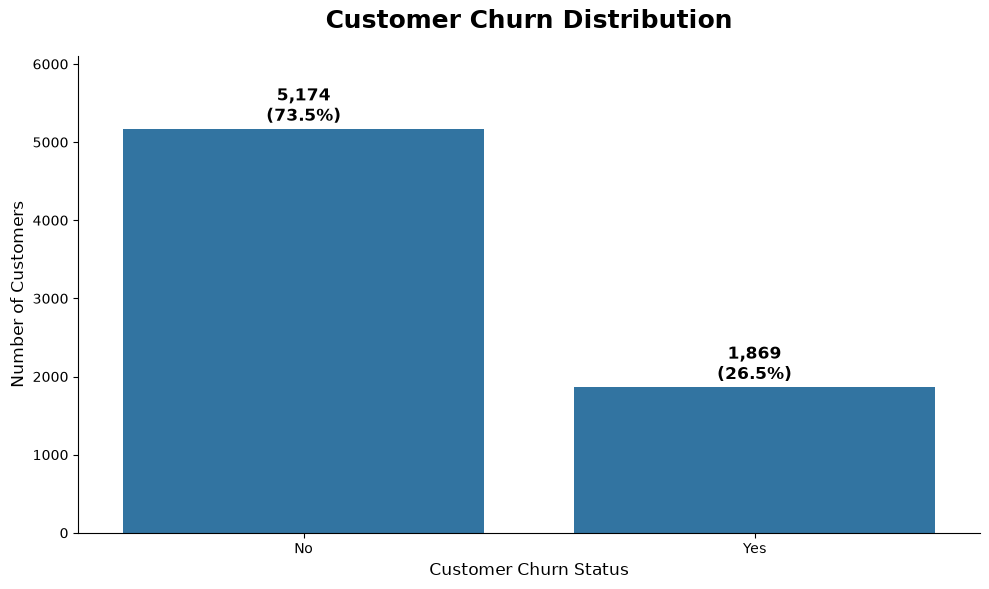

In [21]:
# Calculate churn statistics
churn_counts = df['Churn'].value_counts()
total_customers = len(df)

# Create figure
plt.figure(figsize=(10, 6))

# Create bar chart
ax = sns.barplot(
    x=churn_counts.index,
    y=churn_counts.values
)

# Add count and percentage labels
for i, value in enumerate(churn_counts.values):
    percentage = (value / total_customers) * 100

    ax.text(
        i,
        value + 100,
        f'{value:,}\n({percentage:.1f}%)',
        ha='center',
        fontsize=12,
        fontweight='bold'
    )

# Professional formatting
plt.title(
    'Customer Churn Distribution',
    fontsize=18,
    fontweight='bold',
    pad=20
)

plt.xlabel('Customer Churn Status', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)

plt.ylim(0, max(churn_counts.values) * 1.18)

sns.despine()
plt.tight_layout()

# Save high-resolution graph
plt.savefig(
    'churn_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

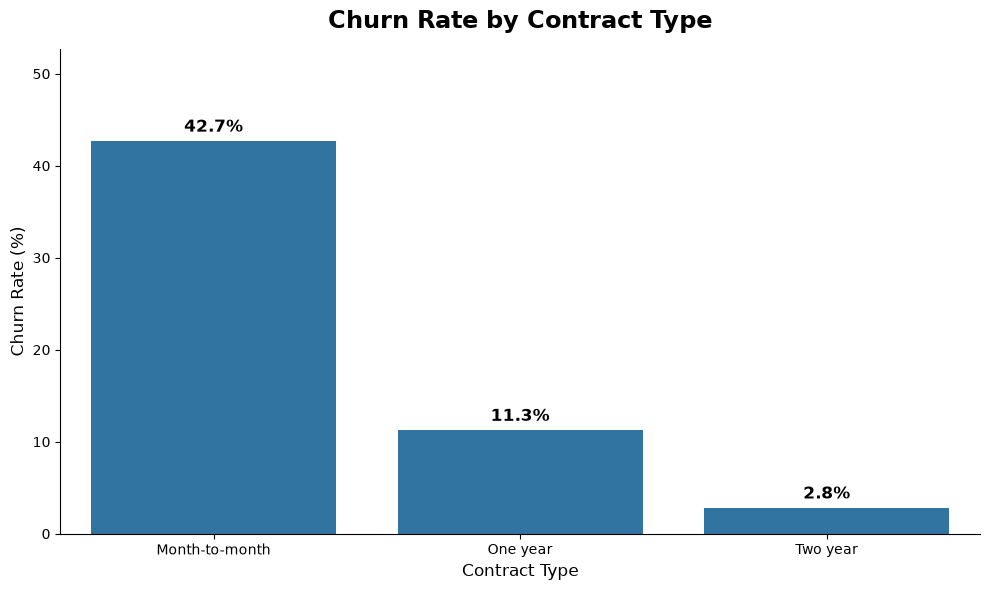

In [22]:
# Calculate churn rate for each contract type
contract_churn = (
    df.groupby('Contract')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .sort_values(ascending=False)
)

# Create professional graph
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values
)

# Add percentage labels
for i, value in enumerate(contract_churn.values):
    ax.text(
        i,
        value + 1,
        f'{value:.1f}%',
        ha='center',
        fontsize=12,
        fontweight='bold'
    )

plt.title('Churn Rate by Contract Type',
          fontsize=17, fontweight='bold', pad=15)

plt.xlabel('Contract Type', fontsize=12)
plt.ylabel('Churn Rate (%)', fontsize=12)
plt.ylim(0, max(contract_churn.values) + 10)

sns.despine()
plt.tight_layout()

plt.savefig('contract_vs_churn.png',
            dpi=300, bbox_inches='tight')

plt.show()

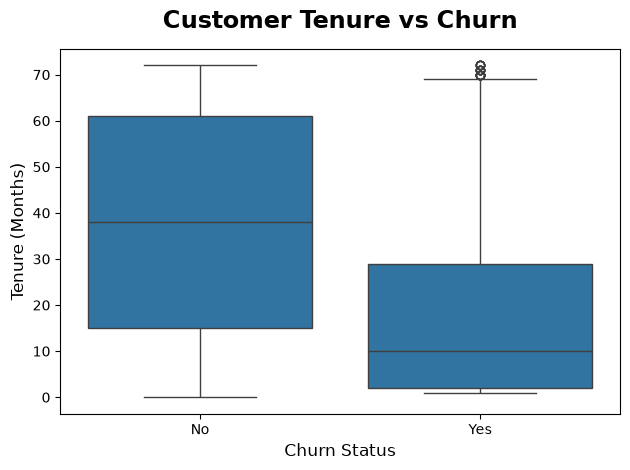

In [24]:
#plt.figure(figsize=(10, 6))

ax = sns.boxplot(
    data=df,
    x='Churn',
    y='tenure'
)

plt.title(
    'Customer Tenure vs Churn',
    fontsize=17,
    fontweight='bold',
    pad=15
)

plt.xlabel('Churn Status', fontsize=12)
plt.ylabel('Tenure (Months)', fontsize=12)

plt.tight_layout()

plt.savefig(
    'tenure_vs_churn.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

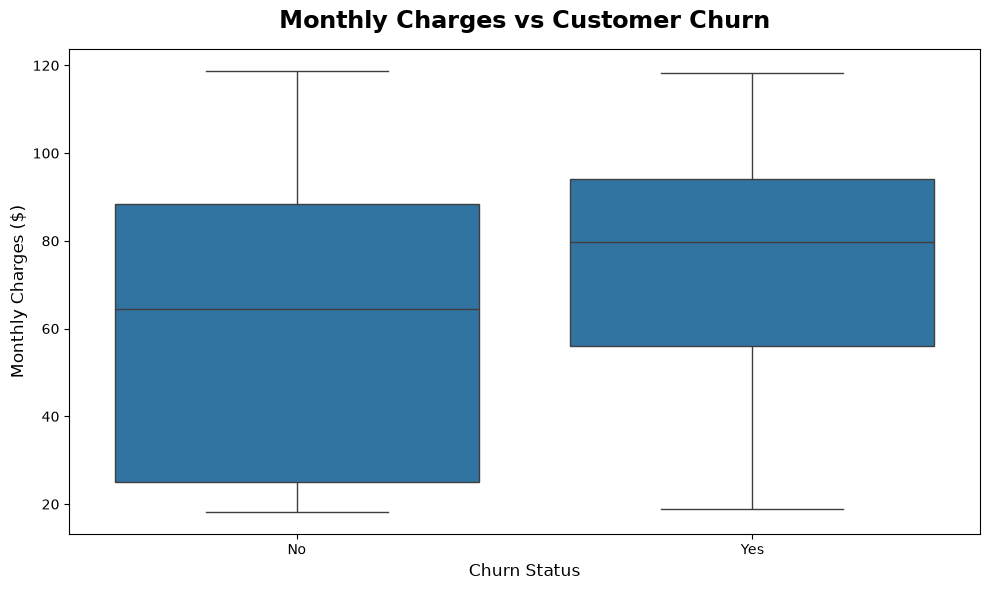

In [25]:
plt.figure(figsize=(10, 6))

ax = sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges'
)

plt.title(
    'Monthly Charges vs Customer Churn',
    fontsize=17,
    fontweight='bold',
    pad=15
)

plt.xlabel('Churn Status', fontsize=12)
plt.ylabel('Monthly Charges ($)', fontsize=12)

plt.tight_layout()

plt.savefig(
    'monthly_charges_vs_churn.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

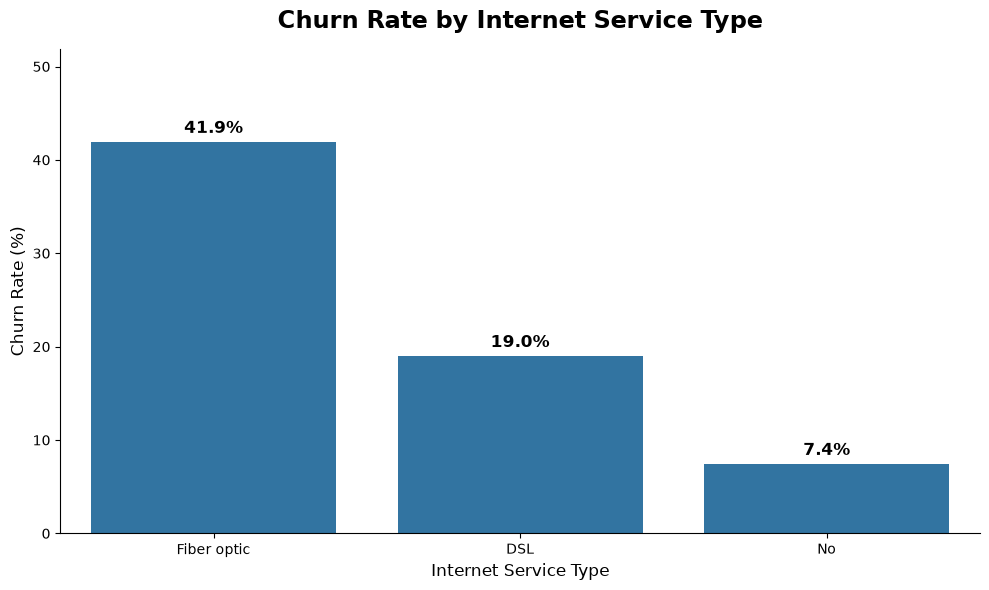

In [26]:
# Calculate churn percentage for each internet service
internet_churn = (
    df.groupby('InternetService')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .sort_values(ascending=False)
)

# Create professional bar chart
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=internet_churn.index,
    y=internet_churn.values
)

# Add percentage labels
for i, value in enumerate(internet_churn.values):
    ax.text(
        i,
        value + 1,
        f'{value:.1f}%',
        ha='center',
        fontsize=12,
        fontweight='bold'
    )

plt.title(
    'Churn Rate by Internet Service Type',
    fontsize=17,
    fontweight='bold',
    pad=15
)

plt.xlabel('Internet Service Type', fontsize=12)
plt.ylabel('Churn Rate (%)', fontsize=12)

plt.ylim(0, max(internet_churn.values) + 10)

sns.despine()
plt.tight_layout()

plt.savefig(
    'internet_service_vs_churn.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

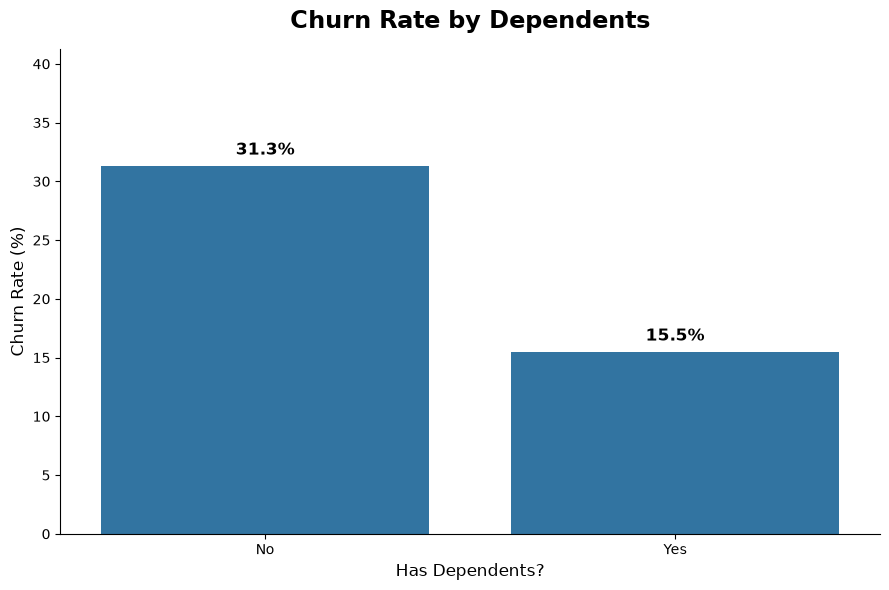

In [27]:
# Calculate churn rate by dependents
dependents_churn = (
    df.groupby('Dependents')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

# Create professional bar chart
plt.figure(figsize=(9, 6))

ax = sns.barplot(
    x=dependents_churn.index,
    y=dependents_churn.values
)

# Add percentage labels
for i, value in enumerate(dependents_churn.values):
    ax.text(
        i,
        value + 1,
        f'{value:.1f}%',
        ha='center',
        fontsize=12,
        fontweight='bold'
    )

plt.title(
    'Churn Rate by Dependents',
    fontsize=17,
    fontweight='bold',
    pad=15
)

plt.xlabel('Has Dependents?', fontsize=12)
plt.ylabel('Churn Rate (%)', fontsize=12)

plt.ylim(0, max(dependents_churn.values) + 10)

sns.despine()
plt.tight_layout()

plt.savefig(
    'dependents_vs_churn.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

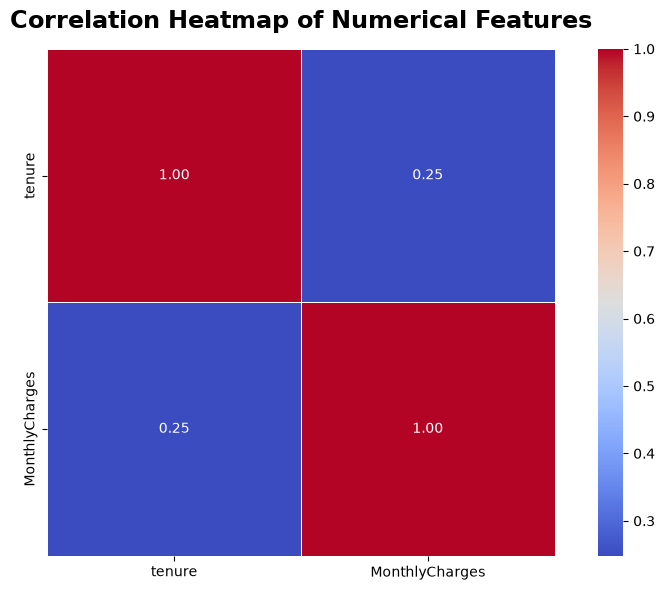

In [28]:
# Select available numerical columns
numeric_data = df[['tenure', 'MonthlyCharges']]

# Calculate correlation
correlation_matrix = numeric_data.corr()

# Create professional heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    square=True
)

plt.title(
    'Correlation Heatmap of Numerical Features',
    fontsize=17,
    fontweight='bold',
    pad=15
)

plt.tight_layout()

plt.savefig(
    'correlation_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [29]:
# Customer Behaviour Analysis

features = [
    'Contract',
    'InternetService',
    'Dependents'
]

for feature in features:

    print("\n" + "=" * 50)
    print(f"Churn Analysis by {feature}")
    print("=" * 50)

    summary = pd.crosstab(
        df[feature],
        df['Churn'],
        normalize='index'
    ) * 100

    print(summary.round(2))


Churn Analysis by Contract
Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83

Churn Analysis by InternetService
Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40

Churn Analysis by Dependents
Churn          No    Yes
Dependents              
No          68.72  31.28
Yes         84.55  15.45


In [30]:
# Compare customer behaviour based on churn status

behaviour_summary = df.groupby('Churn').agg({
    'tenure': 'mean',
    'MonthlyCharges': 'mean'
}).round(2)

print("Customer Behaviour Summary:")
display(behaviour_summary)

Customer Behaviour Summary:


,tenure,MonthlyCharges
Churn,,
No,37.57,61.27
Yes,17.98,74.44


In [31]:
print("========== FINAL EDA SUMMARY ==========")

# Overall churn rate
churn_rate = (df['Churn'] == 'Yes').mean() * 100

print(f"\nOverall Churn Rate: {churn_rate:.2f}%")

# Contract with highest churn
contract_rate = df.groupby('Contract')['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

print("\nChurn Rate by Contract:")
print(contract_rate.round(2))

# Internet service with highest churn
internet_rate = df.groupby('InternetService')['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

print("\nChurn Rate by Internet Service:")
print(internet_rate.round(2))

# Dependents comparison
dependents_rate = df.groupby('Dependents')['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

print("\nChurn Rate by Dependents:")
print(dependents_rate.round(2))

# Average tenure and monthly charges
print("\nAverage Tenure and Monthly Charges:")
print(df.groupby('Churn')[['tenure', 'MonthlyCharges']].mean().round(2))

========== FINAL EDA SUMMARY ==========

Overall Churn Rate: 26.54%

Churn Rate by Contract:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

Churn Rate by Internet Service:
InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: Churn, dtype: float64

Churn Rate by Dependents:
Dependents
No     31.28
Yes    15.45
Name: Churn, dtype: float64

Average Tenure and Monthly Charges:
       tenure  MonthlyCharges
Churn                        
No      37.57           61.27
Yes     17.98           74.44


In [32]:
# Identify important features based on churn rate difference

features = [
    'Contract',
    'InternetService',
    'Dependents',
    'Partner',
    'OnlineSecurity',
    'TechSupport',
    'PaperlessBilling'
]

feature_importance = {}

for feature in features:

    churn_rates = df.groupby(feature)['Churn'].apply(
        lambda x: (x == 'Yes').mean() * 100
    )

    feature_importance[feature] = (
        churn_rates.max() - churn_rates.min()
    )

importance_df = pd.DataFrame(
    list(feature_importance.items()),
    columns=['Feature', 'Churn_Rate_Difference']
)

importance_df = importance_df.sort_values(
    by='Churn_Rate_Difference',
    ascending=False
)

display(importance_df.round(2))

,Feature,Churn_Rate_Difference
0,Contract,39.88
1,InternetService,34.49
4,OnlineSecurity,34.36
5,TechSupport,34.23
6,PaperlessBilling,17.24
2,Dependents,15.83
3,Partner,13.29


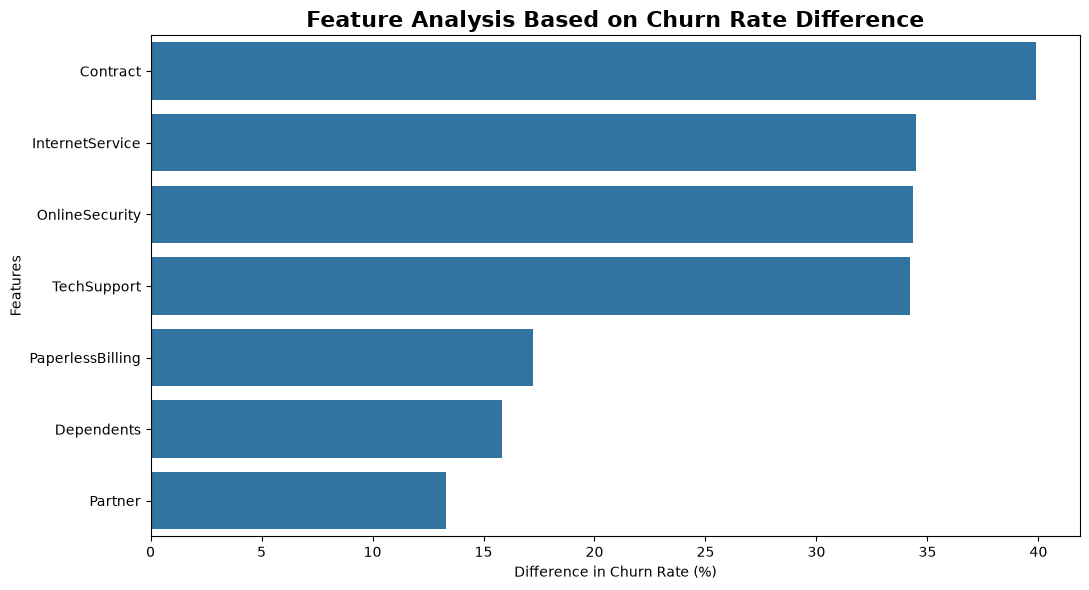

In [33]:
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=importance_df,
    x='Churn_Rate_Difference',
    y='Feature'
)

plt.title(
    'Feature Analysis Based on Churn Rate Difference',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Difference in Churn Rate (%)')
plt.ylabel('Features')

plt.tight_layout()

plt.savefig(
    'important_features.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()